In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('df_ITs_train.csv')

In [3]:
df_test = pd.read_csv('df_ITs_test.csv')

In [4]:
df.head(10)

,department_id,year,tech_stack,current_staff_count,yearly_cv_processed,share_seniors,active_projects_count,inbound_applications,avg_dev_salary,devs_hired,devs_fired,turnover_rate,tech_brand_rating,total_salary_budget
0,1000000.0,2020.0,Стадион,392.0,5847.0,4.591837,231.0,1969.0,110277.784723,77.0,52.0,0.329082,0.6,51877245.0
1,1000000.0,2021.0,Стадион,445.0,6688.0,6.292135,258.0,2415.0,123862.871896,119.0,47.0,0.373034,0.6,66162037.0
2,1000000.0,2022.0,Стадион,514.0,7503.0,7.198444,291.0,2544.0,122932.673766,143.0,60.0,0.394942,0.6,75827728.0
3,1000000.0,2023.0,Стадион,587.0,8272.0,8.858603,327.0,3426.0,123735.907223,103.0,63.0,0.282794,0.8,87165251.0
4,1000001.0,2020.0,Торговый_центр,441.0,7056.0,9.297052,252.0,3565.0,145355.242107,80.0,24.0,0.235828,0.8,76925251.0
5,1000001.0,2021.0,Торговый_центр,510.0,7918.0,8.823529,290.0,3904.0,134199.878106,95.0,55.0,0.294118,0.8,82128749.0
6,1000001.0,2022.0,Торговый_центр,571.0,8804.0,8.756567,312.0,4005.0,124338.545483,82.0,60.0,0.248687,0.6,85200566.0
7,1000001.0,2023.0,Торговый_центр,588.0,9447.0,10.034014,341.0,4558.0,148980.967984,72.0,65.0,0.232993,1.0,105117107.0
8,1000002.0,2020.0,Пляж,322.0,5945.0,16.149068,222.0,2113.0,136123.883173,49.0,17.0,0.204969,0.6,52595842.0
9,1000002.0,2021.0,Пляж,362.0,6884.0,14.917127,250.0,2888.0,141391.878021,43.0,18.0,0.168508,0.6,61421041.0


In [5]:
df['year'].value_counts()

year
2020.0    505
2021.0    505
2022.0    505
2023.0    505
Name: count, dtype: int64

## Распределения признаков

In [6]:
import numpy as np
import matplotlib.pyplot as plt

num_cols = [c for c in df.select_dtypes('number').columns if c not in ('department_id', 'year')]
cat_cols = [c for c in df.columns if c not in num_cols and c != 'department_id']
num_cols, cat_cols

(['current_staff_count',
  'yearly_cv_processed',
  'share_seniors',
  'active_projects_count',
  'inbound_applications',
  'avg_dev_salary',
  'devs_hired',
  'devs_fired',
  'turnover_rate',
  'tech_brand_rating',
  'total_salary_budget'],
 ['year', 'tech_stack'])

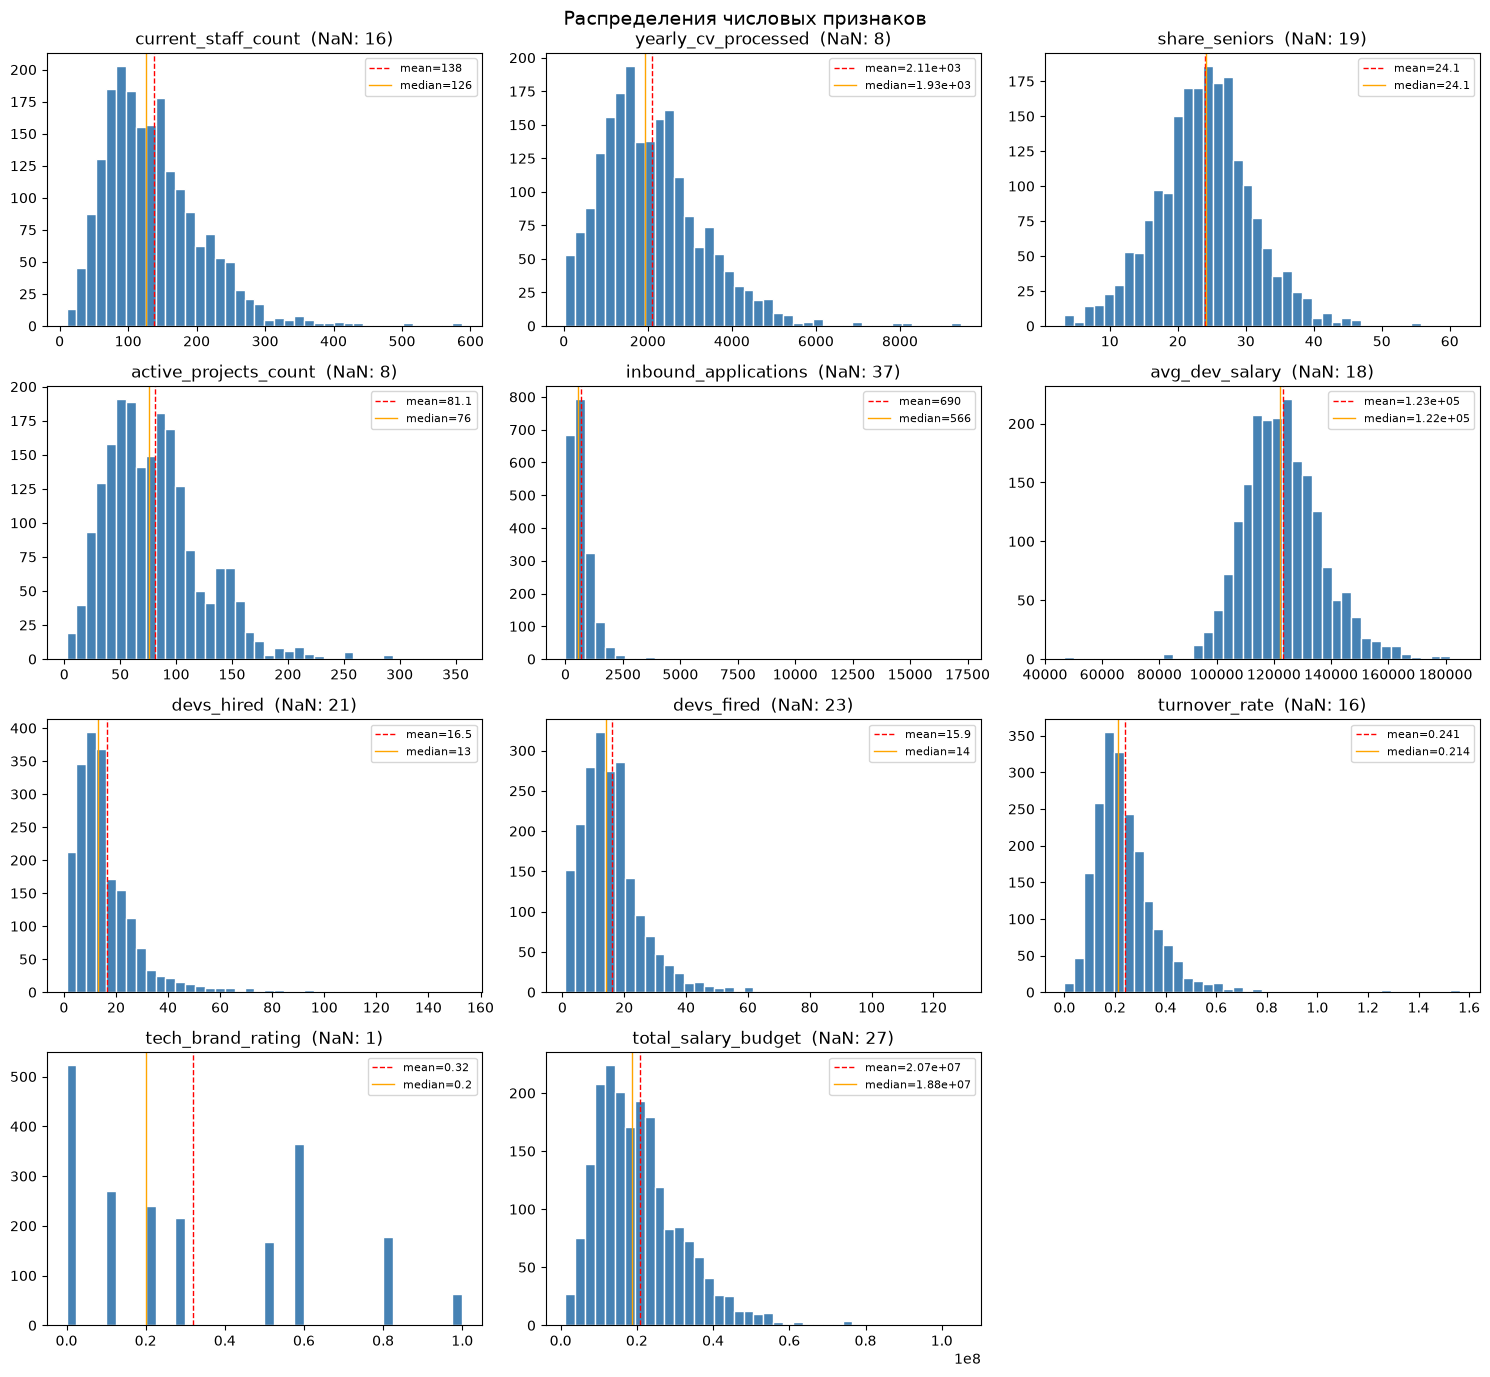

In [7]:
ncols = 3
nrows = int(np.ceil(len(num_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
for ax, col in zip(axes.flat, num_cols):
    s = df[col].dropna()
    ax.hist(s, bins=40, color='steelblue', edgecolor='white')
    ax.axvline(s.mean(), color='red', ls='--', lw=1, label=f'mean={s.mean():.3g}')
    ax.axvline(s.median(), color='orange', ls='-', lw=1, label=f'median={s.median():.3g}')
    ax.set_title(f'{col}  (NaN: {df[col].isna().sum()})')
    ax.legend(fontsize=8)
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle('Распределения числовых признаков', fontsize=14)
fig.tight_layout()
plt.show()

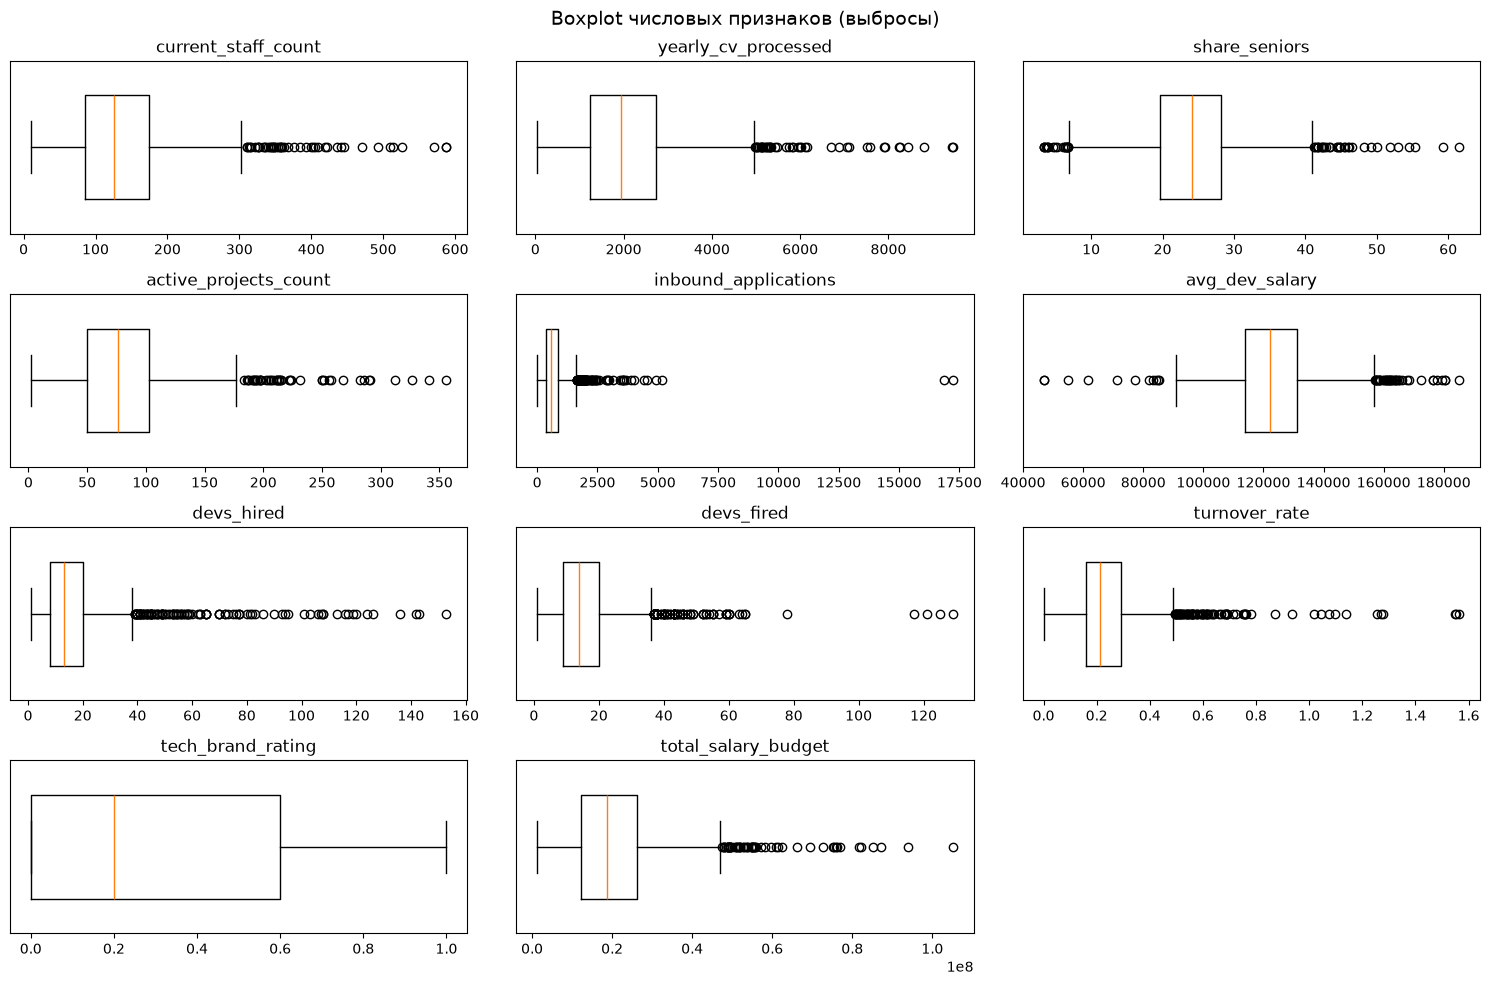

In [8]:
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2.5 * nrows))
for ax, col in zip(axes.flat, num_cols):
    ax.boxplot(df[col].dropna(), orientation='horizontal', widths=0.6)
    ax.set_title(col)
    ax.set_yticks([])
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle('Boxplot числовых признаков (выбросы)', fontsize=14)
fig.tight_layout()
plt.show()

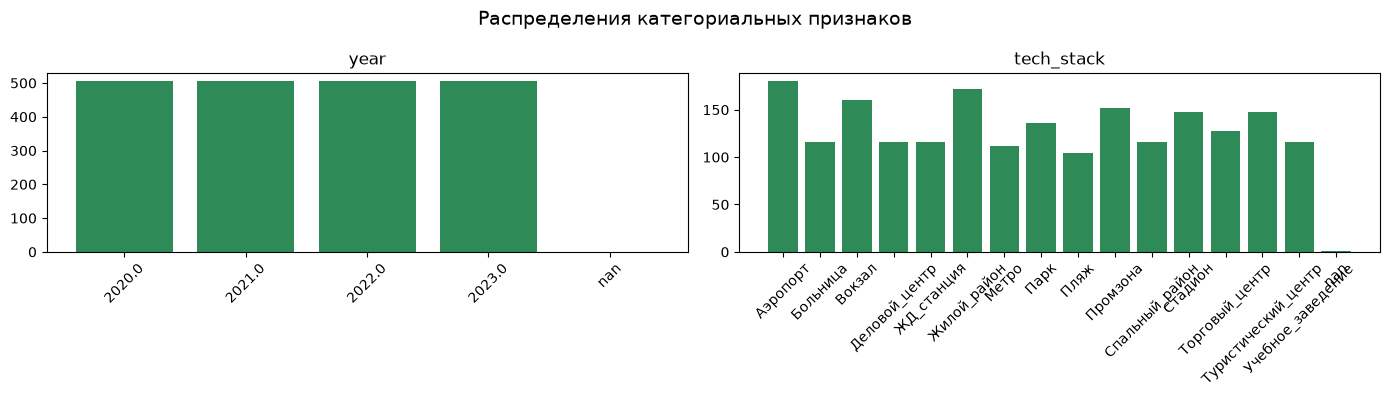

In [9]:
fig, axes = plt.subplots(1, len(cat_cols), figsize=(7 * len(cat_cols), 4))
for ax, col in zip(np.atleast_1d(axes), cat_cols):
    vc = df[col].value_counts(dropna=False).sort_index()
    ax.bar([str(x) for x in vc.index], vc.values, color='seagreen')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
fig.suptitle('Распределения категориальных признаков', fontsize=14)
fig.tight_layout()
plt.show()

## Изменения по годам

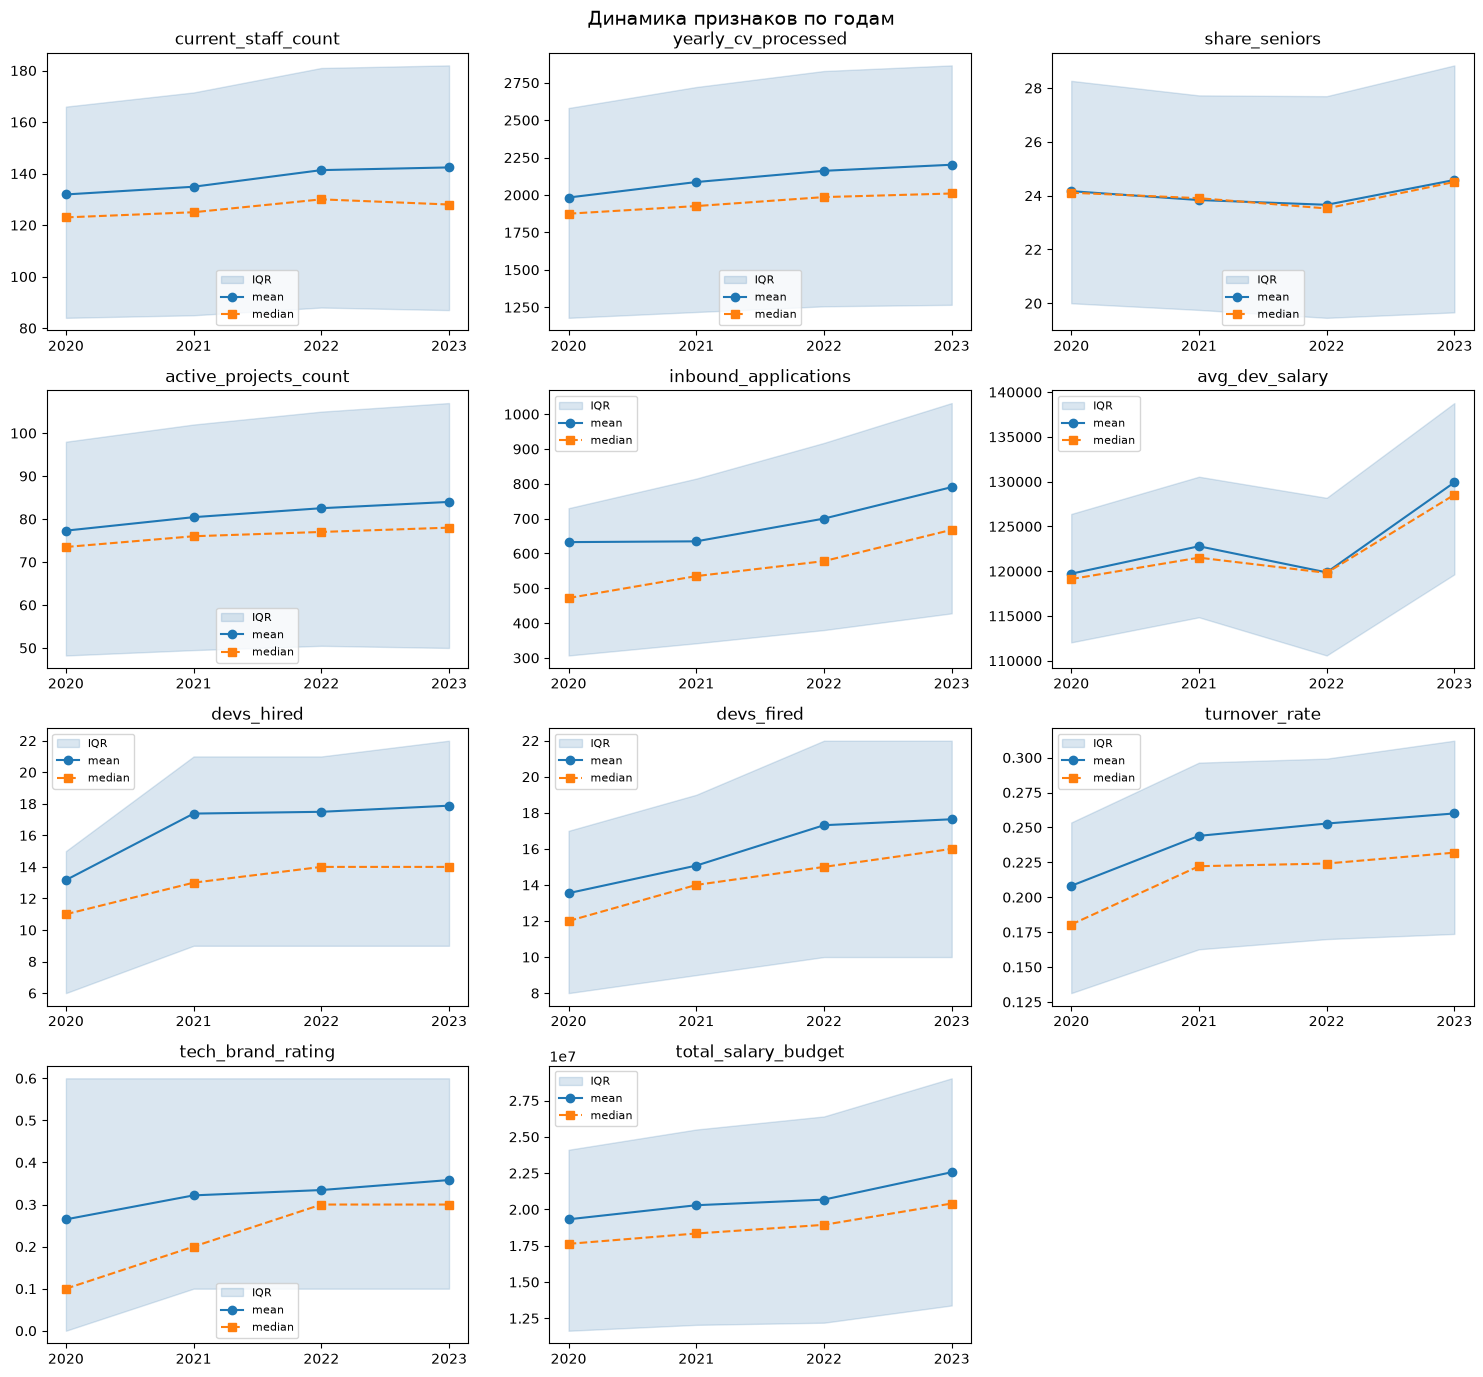

In [10]:
by_year = df.groupby('year')[num_cols].agg(['mean', 'median'])

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
for ax, col in zip(axes.flat, num_cols):
    q = df.groupby('year')[col].quantile([0.25, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.2, color='steelblue', label='IQR')
    ax.plot(by_year.index, by_year[(col, 'mean')], marker='o', label='mean')
    ax.plot(by_year.index, by_year[(col, 'median')], marker='s', ls='--', label='median')
    ax.set_title(col)
    ax.set_xticks(by_year.index)
    ax.legend(fontsize=8)
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle('Динамика признаков по годам', fontsize=14)
fig.tight_layout()
plt.show()

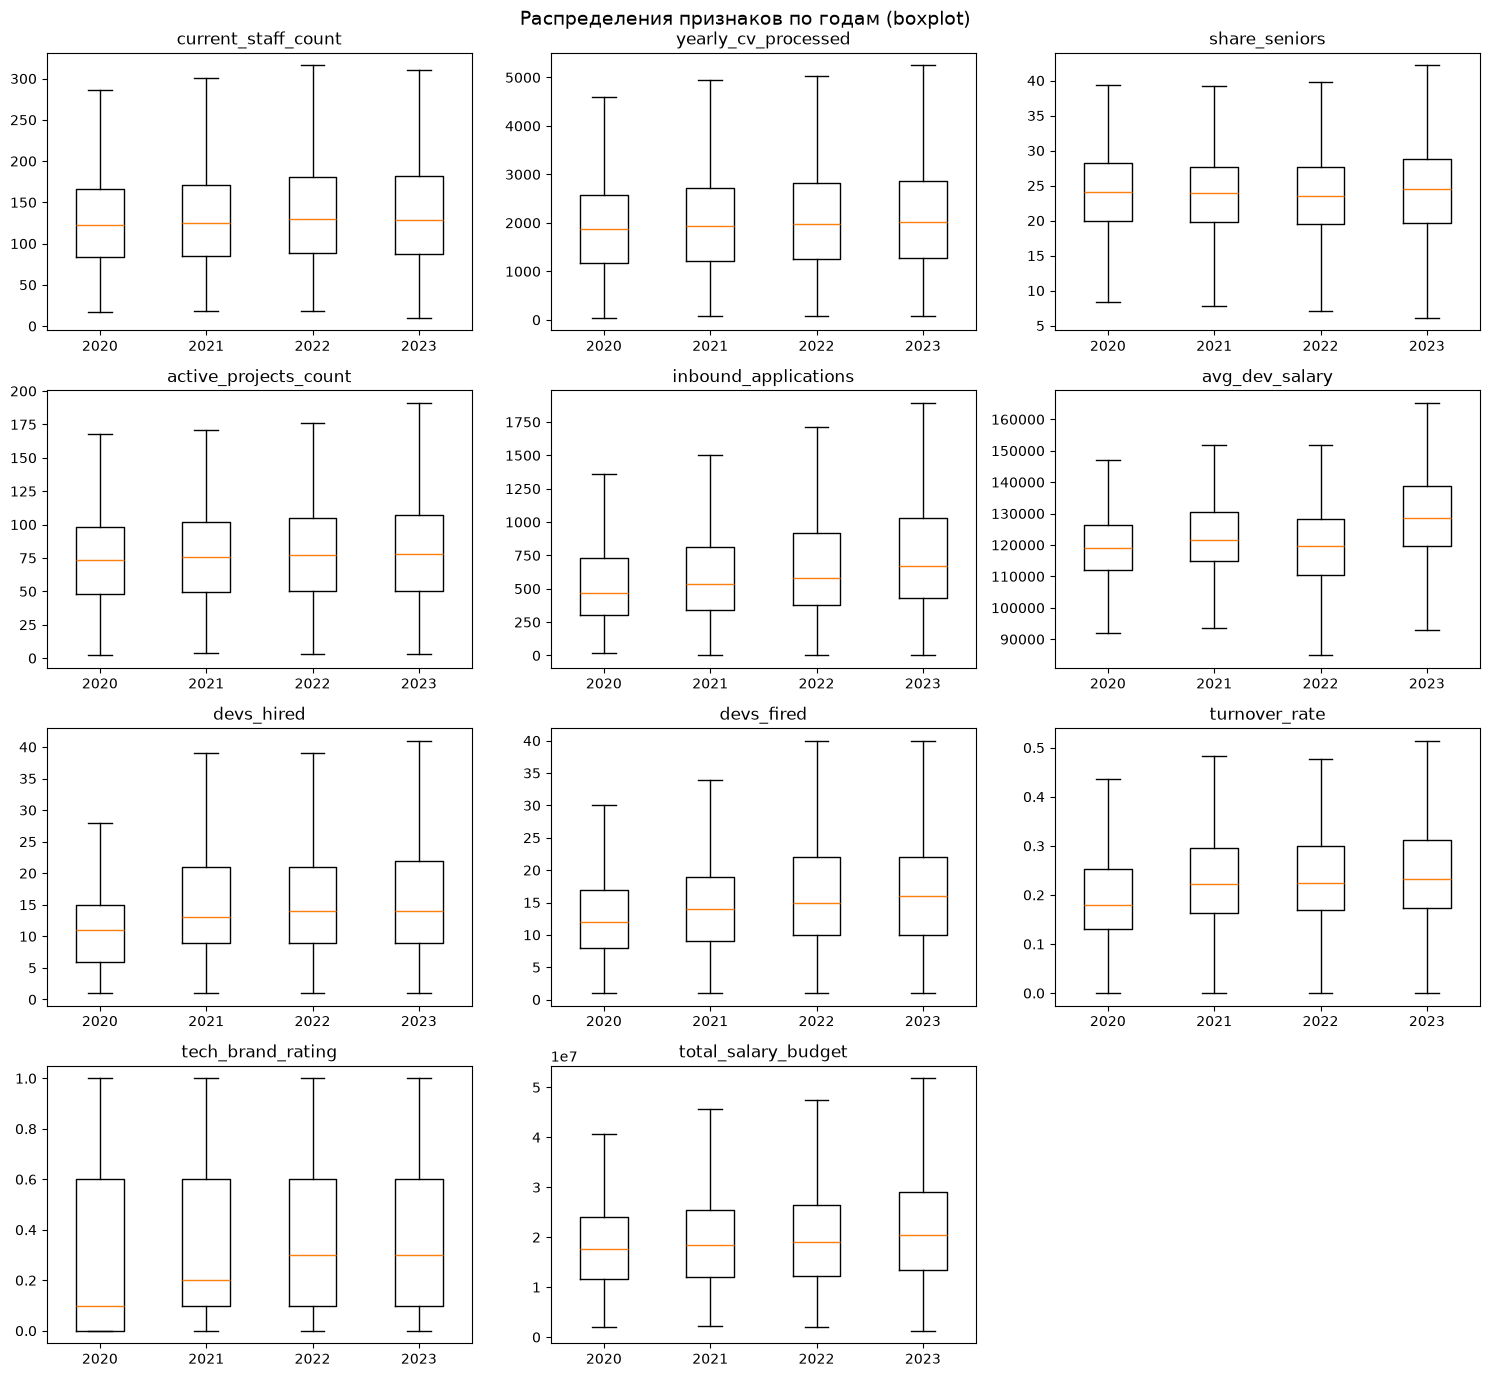

In [11]:
years = sorted(df['year'].dropna().unique())
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
for ax, col in zip(axes.flat, num_cols):
    data = [df.loc[df['year'] == y, col].dropna() for y in years]
    ax.boxplot(data, tick_labels=[int(y) for y in years], showfliers=False)
    ax.set_title(col)
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle('Распределения признаков по годам (boxplot)', fontsize=14)
fig.tight_layout()
plt.show()

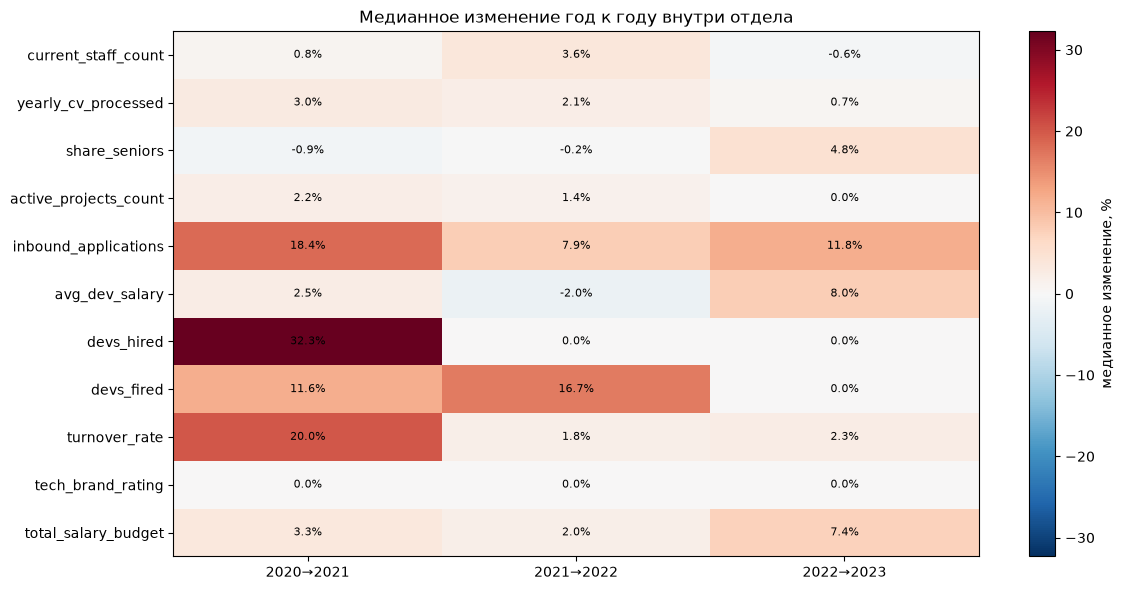

In [12]:
# Средний темп прироста год к году (% изменения внутри каждого отдела)
pct = (df.sort_values(['department_id', 'year'])
         .groupby('department_id')[num_cols].pct_change() * 100)
pct['year'] = df.sort_values(['department_id', 'year'])['year']
yoy = pct.groupby('year')[num_cols].median().dropna(how='all')

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(yoy.T.values, cmap='RdBu_r', aspect='auto',
               vmin=-np.nanmax(np.abs(yoy.values)), vmax=np.nanmax(np.abs(yoy.values)))
ax.set_xticks(range(len(yoy.index)), [f'{int(y)-1}→{int(y)}' for y in yoy.index])
ax.set_yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(yoy.index)):
        v = yoy.iloc[j, i]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.1f}%', ha='center', va='center', fontsize=8)
fig.colorbar(im, label='медианное изменение, %')
ax.set_title('Медианное изменение год к году внутри отдела')
fig.tight_layout()
plt.show()

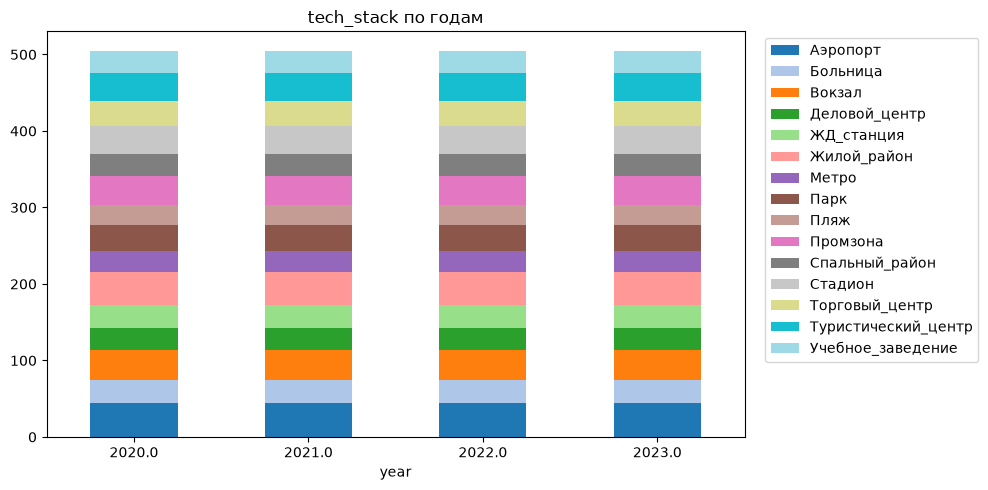

In [13]:
ct = pd.crosstab(df['year'], df['tech_stack'])
ct.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20')
plt.title('tech_stack по годам')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [14]:
df.head(10)

,department_id,year,tech_stack,current_staff_count,yearly_cv_processed,share_seniors,active_projects_count,inbound_applications,avg_dev_salary,devs_hired,devs_fired,turnover_rate,tech_brand_rating,total_salary_budget
0,1000000.0,2020.0,Стадион,392.0,5847.0,4.591837,231.0,1969.0,110277.784723,77.0,52.0,0.329082,0.6,51877245.0
1,1000000.0,2021.0,Стадион,445.0,6688.0,6.292135,258.0,2415.0,123862.871896,119.0,47.0,0.373034,0.6,66162037.0
2,1000000.0,2022.0,Стадион,514.0,7503.0,7.198444,291.0,2544.0,122932.673766,143.0,60.0,0.394942,0.6,75827728.0
3,1000000.0,2023.0,Стадион,587.0,8272.0,8.858603,327.0,3426.0,123735.907223,103.0,63.0,0.282794,0.8,87165251.0
4,1000001.0,2020.0,Торговый_центр,441.0,7056.0,9.297052,252.0,3565.0,145355.242107,80.0,24.0,0.235828,0.8,76925251.0
5,1000001.0,2021.0,Торговый_центр,510.0,7918.0,8.823529,290.0,3904.0,134199.878106,95.0,55.0,0.294118,0.8,82128749.0
6,1000001.0,2022.0,Торговый_центр,571.0,8804.0,8.756567,312.0,4005.0,124338.545483,82.0,60.0,0.248687,0.6,85200566.0
7,1000001.0,2023.0,Торговый_центр,588.0,9447.0,10.034014,341.0,4558.0,148980.967984,72.0,65.0,0.232993,1.0,105117107.0
8,1000002.0,2020.0,Пляж,322.0,5945.0,16.149068,222.0,2113.0,136123.883173,49.0,17.0,0.204969,0.6,52595842.0
9,1000002.0,2021.0,Пляж,362.0,6884.0,14.917127,250.0,2888.0,141391.878021,43.0,18.0,0.168508,0.6,61421041.0


In [ ]:
X_train = df.drop(columns=['department_id', 'yearly_cv_processed'])
y_train = df['yearly_cv_processed']

In [ ]:
X_test = df_test.drop(columns=['department_id', 'yearly_cv_processed'])
y_test = df_test['yearly_cv_processed']

In [16]:
X_train.columns.to_list()

['year',
 'tech_stack',
 'current_staff_count',
 'share_seniors',
 'active_projects_count',
 'inbound_applications',
 'avg_dev_salary',
 'devs_hired',
 'devs_fired',
 'turnover_rate',
 'tech_brand_rating',
 'total_salary_budget']

In [17]:
num_cols = [c for c in X_train.select_dtypes('number').columns]

In [18]:
num_cols

['year',
 'current_staff_count',
 'share_seniors',
 'active_projects_count',
 'inbound_applications',
 'avg_dev_salary',
 'devs_hired',
 'devs_fired',
 'turnover_rate',
 'tech_brand_rating',
 'total_salary_budget']